# Task 4 — Spatial Filtering Masks


In [1]:
# Import and Load Image(s)

import cv2
import numpy as np
import matplotlib.pyplot as plt

def show(images, titles, cols=4):
    n = len(images)
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(4 * cols, 4 * rows))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        if len(img.shape) == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap='gray', vmin=0, vmax=255)
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


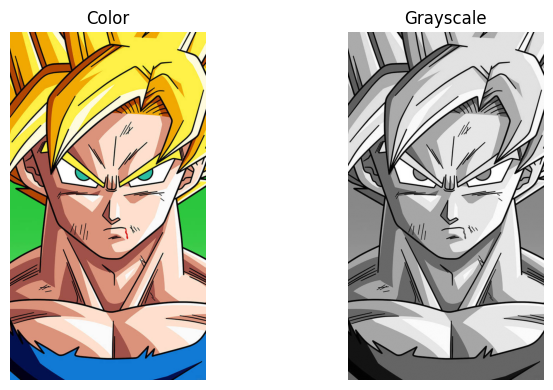

In [2]:
# Load image and convert to grayscale
color = cv2.imread('image1.jpg')
img = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)

show([color, img], ['Color', 'Grayscale'], cols=2)


## Step 2 — Apply the 9 Filters

Each filter slides a small kernel over the image and computes a result for every pixel.

### 4.1 Sobel Filter (edge detection)

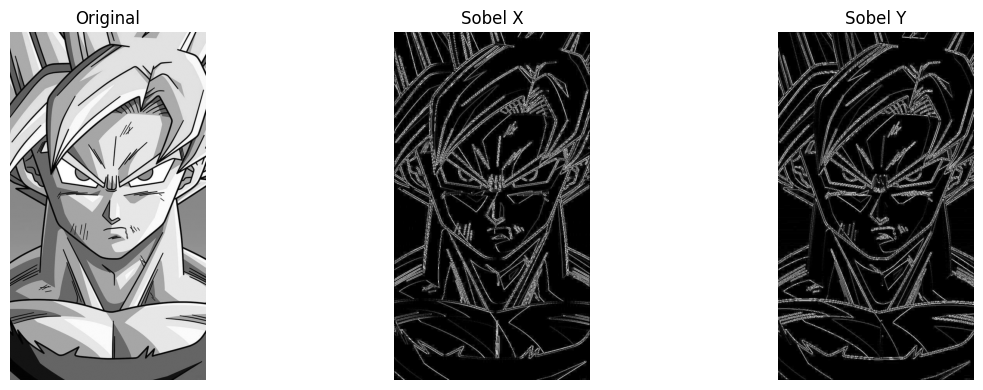

In [3]:
sx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)  # horizontal edges
sy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)  # vertical edges
sx = np.uint8(np.absolute(sx))
sy = np.uint8(np.absolute(sy))
show([img, sx, sy], ['Original', 'Sobel X', 'Sobel Y'])


### 4.2 Box Filter (averaging)

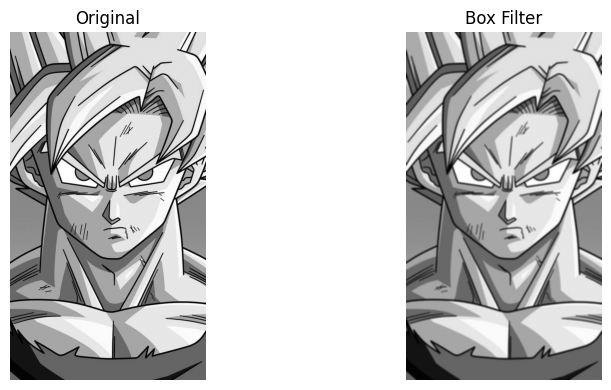

In [4]:
box = cv2.filter2D(img, -1, np.ones((5,5), np.float32) / 25)
show([img, box], ['Original', 'Box Filter'])


### 4.3 Weighted-Average Filter

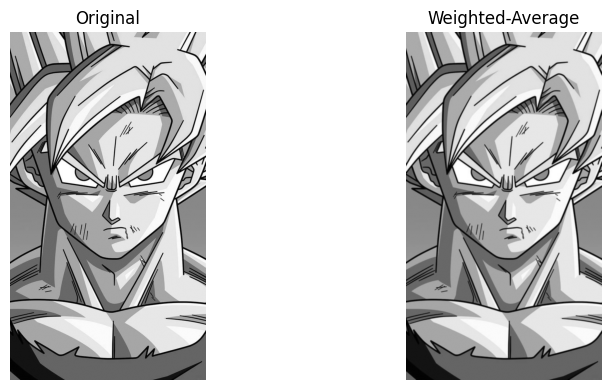

In [5]:
k = np.array([[1,2,1],[2,4,2],[1,2,1]], np.float32) / 16
wavg = cv2.filter2D(img, -1, k)
show([img, wavg], ['Original', 'Weighted-Average'])


### 4.4 Gaussian Filter

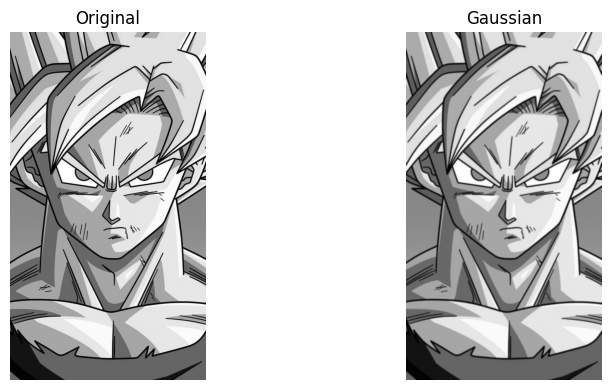

In [6]:
gauss = cv2.GaussianBlur(img, (5,5), 0)
show([img, gauss], ['Original', 'Gaussian'])


### 4.5 Sharpening Filter

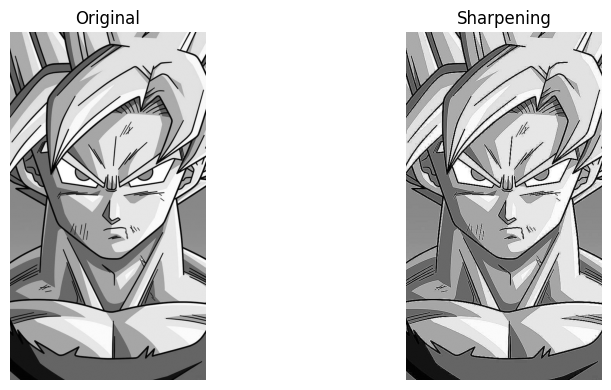

In [7]:
k = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], np.float32)
sharp = cv2.filter2D(img, -1, k)
show([img, sharp], ['Original', 'Sharpening'])


### 4.6 Min Filter (erosion)

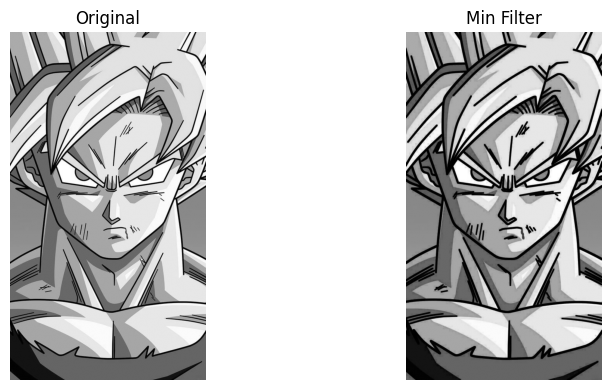

In [8]:
minf = cv2.erode(img, np.ones((3,3), np.uint8))
show([img, minf], ['Original', 'Min Filter'])


### 4.7 Max Filter (dilation)

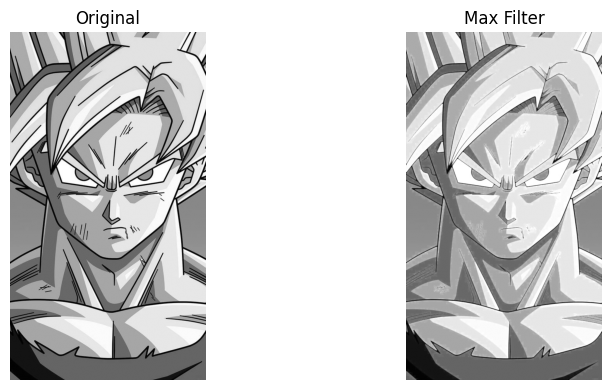

In [9]:
maxf = cv2.dilate(img, np.ones((3,3), np.uint8))
show([img, maxf], ['Original', 'Max Filter'])


### 4.8 Mean Filter

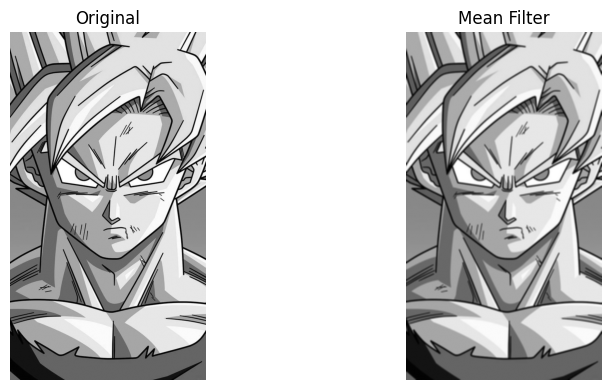

In [10]:
meanf = cv2.blur(img, (5,5))
show([img, meanf], ['Original', 'Mean Filter'])


### 4.9 Median Filter

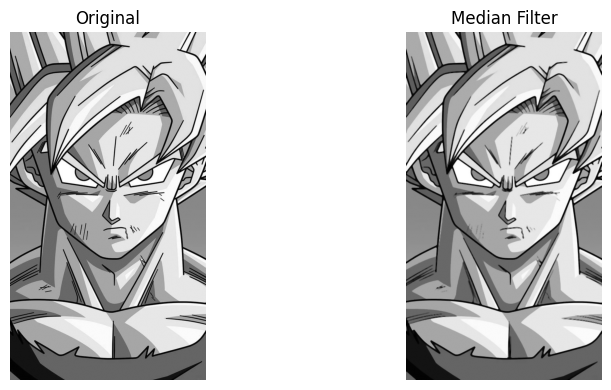

In [11]:
medf = cv2.medianBlur(img, 5)
show([img, medf], ['Original', 'Median Filter'])


### 4.10 All Filters Together

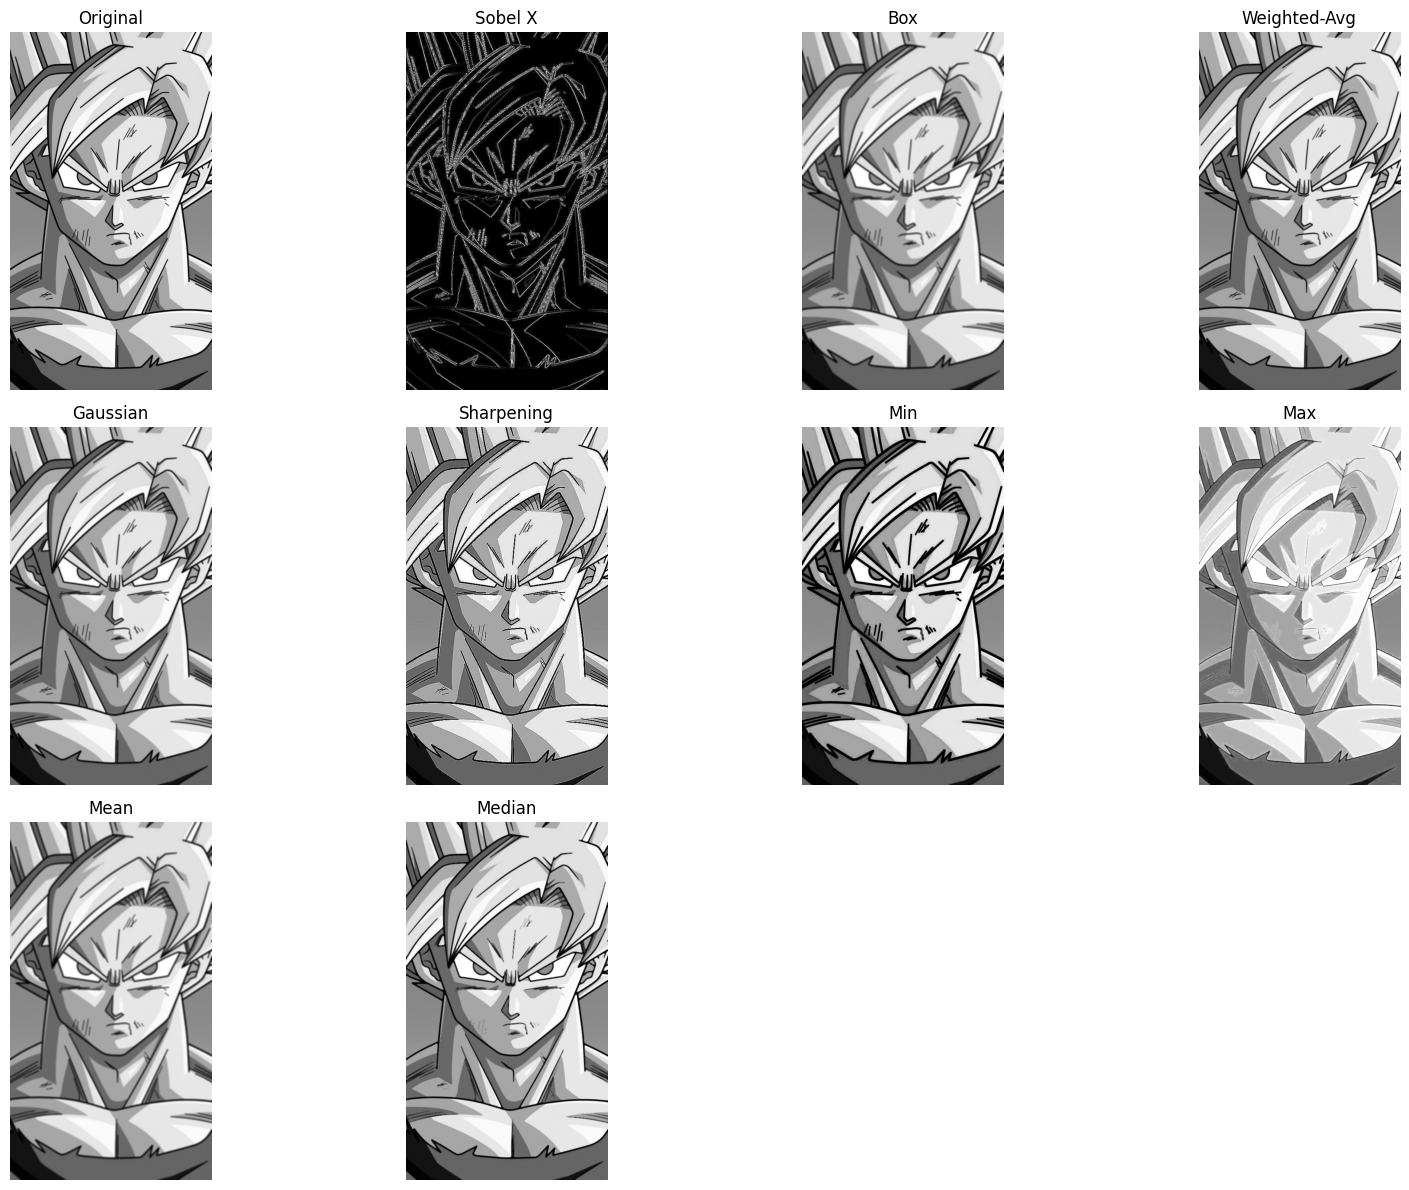

In [12]:
show([img, sx, box, wavg, gauss, sharp, minf, maxf, meanf, medf],
     ['Original','Sobel X','Box','Weighted-Avg','Gaussian',
      'Sharpening','Min','Max','Mean','Median'])
